# PALLAS surrogate models 

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import numpy as np
import pandas as pd
import torch
from torch import nn, optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from skorch import NeuralNetRegressor



## 1. Data loading

In [5]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Relative to your notebook's current working directory.
# Replace with an absolute path if needed.
BASE = Path(
    "../../../artifact-hackathon-2026/challenges/surrogate-models/data_surrogated"
).resolve()

# Search for the full pack, then the sample.
CANDIDATES = [
    Path(os.environ["PALLAS_PACK"]).expanduser()
    if os.environ.get("PALLAS_PACK") else None,
    BASE / "pallas_hackathon_data",
    BASE,
    BASE / "sample",
]

PACK = next(
    (
        candidate
        for candidate in CANDIDATES
        if candidate is not None
        and (candidate / "campaign_A.parquet").is_file()
    ),
    None,
)

if PACK is None:
    raise FileNotFoundError(
        f"No data pack found under {BASE}\n"
        f"Current working directory: {Path.cwd()}\n"
        "Set BASE to the absolute path of your data_surrogated directory."
    )

# Validate the files and columns against the schema.
schema_path = BASE / "ontologies" / "pack_schema.json"

with schema_path.open(encoding="utf-8") as fh:
    SCHEMA = json.load(fh)

for name, spec in SCHEMA["files"].items():
    path = PACK / name

    if not path.is_file():
        raise FileNotFoundError(f"Required file is missing: {path}")

    if name.endswith(".parquet"):
        available = set(pq.ParquetFile(path).schema_arrow.names)
        missing = set(spec["columns"]) - available

        if missing:
            raise ValueError(f"{name} lacks columns: {sorted(missing)}")

# Load only scalar columns, excluding spectra and density curves.
SCALARS = [
    "scan", "config", "p_1", "a_0", "c_N2", "x_of",
    "P_max", "cN2_max", "L_inj", "dip_frac",
    "E_med_MeV", "E_mean_MeV", "dE_mad", "dE_std",
    "q_pC", "q_end", "i_peak",
    "sigma_z", "sigma_y", "n_emit_x", "n_emit_y",
    "div_rms", "injected",
]

def load(name):
    path = PACK / f"{name}.parquet"
    available = pq.ParquetFile(path).schema_arrow.names
    columns = [column for column in SCALARS if column in available]
    return pd.read_parquet(path, columns=columns)

A = load("campaign_A")
B = load("campaign_B")
grid = np.load(PACK / "common_energy_grid_MeV.npy")

print(f"Data folder: {PACK}")
print(f"Campaign A: {len(A):,} simulations")
print(f"Campaign B: {len(B):,} simulations")

if PACK == BASE / "sample":
    print("Using the 10% sample.")

display(A.head())
display(B.head())

Data folder: /home/qou/AI_Hackathon/artifact-hackathon-2026/challenges/surrogate-models/data_surrogated/pallas_hackathon_data
Campaign A: 13,073 simulations
Campaign B: 5,286 simulations


,scan,config,p_1,a_0,c_N2,x_of,E_med_MeV,E_mean_MeV,dE_mad,dE_std,q_pC,q_end,i_peak,sigma_z,sigma_y,n_emit_x,n_emit_y,div_rms,injected
0,random,11,51.967970,1.328588,0.031888,740.016691,176.890297,182.658976,0.062651,0.108350,150.826672,1.508267e-10,7701.320948,0.000002,0.000002,0.000001,0.000004,0.005604,True
1,random,101,81.175615,1.278433,0.041408,914.823751,117.437183,113.083162,0.187095,0.234163,272.069986,2.720700e-10,12166.720834,0.000003,0.000004,0.000004,0.000007,0.011650,True
2,random,1001,33.709236,1.100172,0.061323,731.207475,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,random,1002,68.886697,1.195013,0.072505,560.282091,89.495034,89.469613,0.372771,0.455383,270.789954,2.707900e-10,9867.215564,0.000005,0.000005,0.000006,0.000011,0.016154,True
4,random,1003,97.236441,1.116539,0.103158,790.421058,115.507544,101.976347,0.207592,0.398384,194.815044,1.948150e-10,8616.965730,0.000006,0.000008,0.000016,0.000020,0.017338,True


,config,a_0,x_of,P_max,cN2_max,L_inj,dip_frac,E_med_MeV,E_mean_MeV,dE_mad,dE_std,q_pC,q_end,i_peak,sigma_z,sigma_y,n_emit_x,n_emit_y,div_rms,injected
0,1065,1.25,1492.414048,4029.926805,0.071580,0.400605,0.118237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1098,1.25,1711.534893,4266.843694,0.066978,0.566518,0.378512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1093,1.25,1643.475844,4111.595115,0.096340,0.438924,0.333832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1011,1.25,1546.986129,4956.362657,0.076182,0.560563,0.158826,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,100,1.25,1632.619931,4058.131647,0.106004,0.511939,0.294766,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [6]:
def targets_to_normalised(frame, targets):
    """The targets as the scorer sees them: log10 for charge and spread, energy unchanged. Fit on these."""
    return np.column_stack([physical_to_normalised(t, frame[t]) for t in targets])


def predictions_to_physical(pred, targets):
    """Model output back to physical units, the units a submission is written in."""
    return pd.DataFrame({t: normalised_to_physical(t, pred[:, i]) for i, t in enumerate(targets)})


## Objective Easy: 2

In [7]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size, output_size):
        super(NeuralNetwork, self).__init__()

        # Define the first hidden layer 
        self.hidden1 = nn.Linear(input_size, 128)
        # Define the second and third hidden layers 
        self.hidden2 = nn.Linear(128, 64)
        self.hidden3 = nn.Linear(64, 32)      
        # Define the output layer (64 neurons to output_size)
        self.output = nn.Linear(32, output_size)

    # Define the forward pass
    def forward(self, x):
        # Apply the  ReLU activations
        x = F.relu(self.hidden1(x))
        x = F.relu(self.hidden2(x))
        x = F.relu(self.hidden3(x))
        x = self.output(x)
        
        return x
    

In [8]:
class NeuralNetworkDropout(nn.Module):
    def __init__(self, input_size, output_size, dropout=0.1):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(p=dropout),

            nn.Linear(128, 64),
            nn.ReLU(),

            # Linear output for regression
            nn.Linear(64, output_size),
        )

    def forward(self, x):
        return self.layers(x)

In [9]:
# Ensure PyTorch receives float32 arrays
def to_float32(X):
    return np.asarray(X, dtype=np.float32)


# Select features and targets
inputs_B = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of"]
outputs_B = ["E_med_MeV", "dE_mad", "q_end"]

B_clean = B.dropna(subset=inputs_B + outputs_B)

train, test = train_test_split(
    B_clean,
    test_size=0.2,
    random_state=0,
)

# These data remain in their original physical units
x_train = train[inputs_B]
y_train = train[outputs_B].to_numpy(dtype=np.float32)

x_test = test[inputs_B]
y_test = test[outputs_B]






In [10]:
# Define the PyTorch regressor
device = "cuda" if torch.cuda.is_available() else "cpu"

net = NeuralNetRegressor(
    module=NeuralNetwork,
    module__input_size=len(inputs_B),     # 5 inputs
    module__output_size=len(outputs_B),   # 3 outputs
    criterion=nn.MSELoss,
    optimizer=optim.Adam,
    lr=0.001,
    max_epochs=300,
    batch_size=32,
    iterator_train__shuffle=True,
    train_split=None,  # Train on all supplied training samples
    device=device,
    verbose=1,
)

# net = NeuralNetRegressor(
#     module=NeuralNetworkDropout,
#     module__input_size=len(inputs_B),
#     module__output_size=len(outputs_B),
#     module__dropout=0.1,
#     criterion=nn.MSELoss,
#     optimizer=torch.optim.Adam,
#     lr=0.001,
#     max_epochs=300,
#     batch_size=32,
#     iterator_train__shuffle=True,
#     train_split=None,
#     device=device,
#     verbose=1,
# )

In [11]:

# Input scaling followed by the neural network
input_pipeline = Pipeline([
    ("input_scaler", StandardScaler()),
    ("float32", FunctionTransformer(to_float32)),
    ("network", net),
])


# Target scaling and automatic inverse transformation
model = TransformedTargetRegressor(
    regressor=input_pipeline,
    transformer=StandardScaler(),
)


# Train directly using unscaled data
model.fit(x_train, y_train)


# Predict directly using unscaled data:
# predictions are automatically returned in physical units
y_pred = model.predict(x_test)

predictions = pd.DataFrame(
    y_pred,
    columns=outputs_B,
    index=x_test.index,
)

print(predictions.head())

  epoch    train_loss     dur
-------  ------------  ------
      1        0.5576  0.1086
      2        0.1657  0.1153
      3        0.0837  0.1919
      4        0.0501  0.1061
      5        0.0420  0.1155
      6        0.0387  0.1142
      7        0.0289  0.1150
      8        0.0264  0.1139
      9        0.0236  0.1144
     10        0.0222  0.1245
     11        0.0205  0.1197
     12        0.0194  0.1374
     13        0.0177  0.1320
     14        0.0176  0.1317
     15        0.0175  0.1311
     16        0.0159  0.1309
     17        0.0149  0.1309
     18        0.0174  0.1316
     19        0.0141  0.1309
     20        0.0139  0.1300
     21        0.0131  0.1307
     22        0.0127  0.1296
     23        0.0140  0.1225
     24        0.0120  0.1323
     25        0.0115  0.1320
     26        0.0268  0.1308
     27        0.0144  0.1309
     28        0.0115  0.1306
     29        0.0104  0.1318
     30        0.0100  0.1211
     31        0.0100  0.1251
     32   

    252        0.0024  0.1057
    253        0.0032  0.1380
    254        0.0026  0.1398
    255        0.0049  0.1354
    256        0.0025  0.1373
    257        0.0024  0.1214
    258        0.0023  0.1384
    259        0.0024  0.1420
    260        0.0032  0.0664
    261        0.0101  0.0630
    262        0.0031  0.0648
    263        0.0031  0.0595
    264        0.0026  0.1374
    265        0.0039  0.1182
    266        0.0024  0.1379
    267        0.0022  0.1267
    268        0.0025  0.1385
    269        0.0060  0.1505
    270        0.0024  0.1449
    271        0.0022  0.1159
    272        0.0029  0.1509
    273        0.0021  0.1486
    274        0.0019  0.1441
    275        0.0021  0.1440
    276        0.0020  0.1380
    277        0.0036  0.1376
    278        0.0024  0.1357
    279        0.0020  0.1370
    280        0.0018  0.1304
    281        0.0022  0.1432
    282        0.0020  0.1398
    283        0.0020  0.1405
    284        0.0052  0.0657
    285   

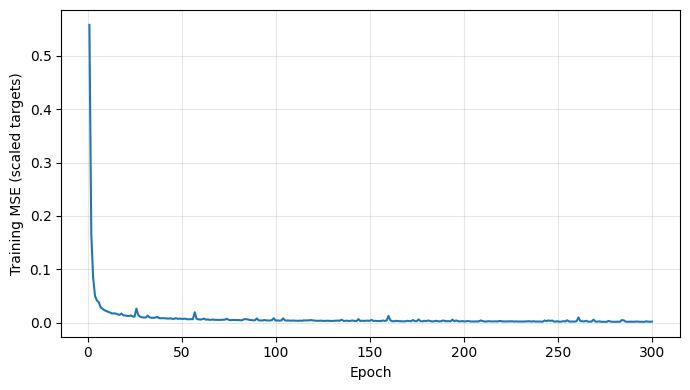

In [12]:
import matplotlib.pyplot as plt

# Access the fitted network
fitted_net = model.regressor_.named_steps["network"]

epochs = fitted_net.history[:, "epoch"]
loss_history = fitted_net.history[:, "train_loss"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, loss_history)
ax.set_xlabel("Epoch")
ax.set_ylabel("Training MSE (scaled targets)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

# Predictions in original physical units
y_pred = model.predict(x_test)

# One R² score per output, in outputs_B order
r2_individual = r2_score(
    y_test,
    y_pred,
    multioutput="raw_values",
)

r2_results = pd.Series(
    r2_individual,
    index=outputs_B,
    name="Test R²",
)

print(r2_results)
print(f"\nMean test R²: {np.mean(r2_individual):.4f}")

E_med_MeV    0.997230
dE_mad       0.976875
q_end        0.998316
Name: Test R², dtype: float32

Mean test R²: 0.9908


In [14]:
import pandas as pd

# Load submission inputs — adjust the filename if necessary
submission_inputs = pd.read_parquet(f"{PACK}/test_direct.parquet")

# Predict using the same feature order as during training
submission = pd.DataFrame(
    model.predict(submission_inputs[inputs_B]),
    columns=outputs_B,
)

# Include the configuration identifier
submission.insert(0, "config", submission_inputs["config"].to_numpy())

# Save without the DataFrame index
submission.to_csv("submission_direct.csv", index=False)

print(f"Wrote submission_direct.csv ({len(submission):,} rows)")
print(submission.head())

Wrote submission_direct.csv (357 rows)
   config   E_med_MeV    dE_mad         q_end
0    1041  116.673599  0.048130  1.210838e-10
1    1109  120.157814  0.039811  1.413341e-10
2    1088  120.131897  0.036242  1.262448e-10
3     103  163.612762  0.037649  8.673890e-11
4    1031  184.214920  0.086506  2.189172e-11


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Use the same input scaling as during training
device = next(model.parameters()).device
X_test_tensor = torch.as_tensor(
    np.asarray(X_test_scaled), dtype=torch.float32, device=device
)

model.eval()
with torch.no_grad():
    y_pred = model(X_test_tensor).cpu().numpy()

# Ground-truth targets, in the same scaled space as the predictions
if torch.is_tensor(y_test_scaled):
    y_true = y_test_scaled.detach().cpu().numpy()
else:
    y_true = np.asarray(y_test_scaled)

# If targets were scaled, convert BOTH arrays to physical units.
# Replace y_scaler with the scaler fitted on your training targets.
y_pred = y_scaler.inverse_transform(y_pred)
y_true = y_scaler.inverse_transform(y_true)

# Support both single-output and multi-output regression
if y_true.ndim == 1:
    y_true = y_true[:, None]
    y_pred = y_pred[:, None]

target_names = [f"Output {i + 1}" for i in range(y_true.shape[1])]
fig, axes = plt.subplots(
    1, len(target_names),
    figsize=(5 * len(target_names), 4),
    squeeze=False
)

for i, ax in enumerate(axes.ravel()):
    ax.scatter(y_true[:, i], y_pred[:, i], s=12, alpha=0.4)

    lo = min(y_true[:, i].min(), y_pred[:, i].min())
    hi = max(y_true[:, i].max(), y_pred[:, i].max())
    ax.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")

    ax.set(
        xlabel="Real value",
        ylabel="Predicted value",
        title=target_names[i],
        xlim=(lo, hi),
        ylim=(lo, hi)
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

AttributeError: 'TransformedTargetRegressor' object has no attribute 'parameters'